<a href="https://colab.research.google.com/github/sugarfreecat/festival-musica/blob/main/notebooks/01_analise_exploratoria_vendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Exploratória Aplicada Com Python

## Pergunta de Negócio

### Quais gêneros musicais apresentam maior média de ingressos vendidos em cada mês do ano?

Colunas de análise: genero_musical (dimensão) e data_hora_venda (fato)

Decisão que o resultado apoiaria: o planejamento da programação de eventos de acordo com a sazonalidade de consumo do público

### Quais canais de venda apresentam maior volume de ingressos vendidos e maior faturamento?

Colunas de análise: canal_venda (fato), valor (fato)

Decisão que o resultado apoiaria: direcionar recursos de marketing para canais com maior potencial de geração de receita, identificar canais com baixo volume de vendas ou faturamento para investigar e identificar oportunidades de melhoria

## Preparando o Ambiente

In [ ]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

## Carregando os Arquivos CSV

O que esta célula faz: conecta o Google Drive, guarda os CSV na pasta Colab Notebooks/desafios/dados e lê os dois arquivos em DataFrames: df_dimensao e df_fato. Os nomes das tabelas são os mesmos dos arquivos, sem o .csv.

Na primeira execução, o Colab pede autorização para acessar o Drive.
Se algum arquivo ainda não estiver na pasta, abre a janela de seleção: escolha os 2 CSV de uma vez. O código identifica cada um pelo nome (o nome do arquivo precisa conter o nome da tabela) e salva já com o nome certo.
Nas próximas execuções, lê direto do Drive, sem pedir envio.

In [ ]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)
print("-----------")
print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-----------
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


## Conhecendo a Tabela Dimensão

Lembrete: A tabela dimensão é aquela que descreve as coisas de um tema, onde cada linha é um item único e as colunas descrevem suas propriedades.

Neste caso, a tabela dimensão é a de atrações, que descreve todos os festivais disponíveis na base de dados

In [ ]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


## Conhecendo a Tabela Fato

Lembrete: A tabela fato lista ocorrências de eventos relacionados aos itens únicos da tabela dimensão.

In [ ]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


### Criando as Colunas Mês e Ano

Para fazer a análise de média de vendas de ingressos ao longo dos meses nos últimos anos, é necessário extrair colunas referentes ao mês e ao ano da venda do ingresso a partir de data_hora_venda.

In [ ]:
meses_pt = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr',
    5: 'Mai', 6: 'Jun', 7: 'Jul', 8: 'Ago',
    9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'
}

# converte a coluna de objeto para datetime (necessário para extrair o mês da data completa)
df_fato['data_hora_venda'] = pd.to_datetime(df_fato['data_hora_venda'])

# extrai o mês e o ano
df_fato['mes_venda'] = df_fato['data_hora_venda'].dt.month.map(meses_pt)
df_fato["ano_venda"] = df_fato['data_hora_venda'].dt.year

display(df_fato.head())

,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento,mes_venda,ano_venda
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix,Nov,2022
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito,Abr,2026
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix,Nov,2022
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito,Abr,2021
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix,Jan,2020


### 📅 Ajustando a Ordem Correta dos Meses

In [ ]:
ordem_dos_meses = [
    'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
    'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'
]

df_fato['mes_venda'] = pd.Categorical(
    df_fato['mes_venda'],
    categories=ordem_dos_meses,
    ordered=True
)

## Verificando Os Datasets

### Tipos dos Dados

In [ ]:
df_fato.dtypes

,0
venda_id,int64
atracao_id,int64
tipo_ingresso,object
canal_venda,object
data_hora_venda,object
valor,float64
forma_pagamento,object


### Valores Ausentes

In [ ]:
print("Valores ausentes por coluna:")
print(df_fato.isna().sum())

Valores ausentes por coluna:
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64


### Linhas Duplicadas

In [ ]:
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Chave Estrangeira
Todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.

In [ ]:
COLUNA_FK = "atracao_id"        # coluna da fato que referencia a dimensão
COLUNA_ID = "atracao_id"   # coluna de ID da dimensão

# checa se FK de cada linha da tabela fato existe como PK na tabela dimensão
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Leitura da Conferência

**Leitura da conferência**

- (tamanho da tabela fato e se há linhas duplicadas)
- (se a chave estrangeira bate com a dimensão)
- (se a coluna de análise tem valores ausentes)
- (se há valores ausentes em outras colunas e por que estão vazios: erro ou não)

## Coluna Numérica (Valor)

### Verificando Valores Ausentes

In [ ]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Medidas Estatísticas

In [ ]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


### Insights

- **A média de (coluna) é (valor)**. (O que a média significa para o seu tema.)

- **A mediana de (coluna) é (valor)**. (O que a mediana mostra e como ela se compara à média.)

- **O desvio padrão de (coluna) é (valor)**. (O que a variação mostra.)

- **Decisão final:** (escreva uma frase com a decisão que as três medidas apoiam.)

## Juntando as Duas Tabelas

A tabela completa continuará listando todas as vendas de ingressos da tabela fato, porém com o adicional de informações vindas da tabela dimensão.

In [ ]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais
df_completo.head()

Linhas da fato: 55000 | depois da junção: 55000


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento,mes_venda,ano_venda,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix,Nov,2022,Farias,rock,Festival Fuga 2022,2022-11-13,secundario,19:30
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito,Abr,2026,As Silveira,eletronica,Festival Neque 2026,2026-04-27,principal,22:00
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix,Nov,2022,As Vieira,sertanejo,Festival Fuga 2022,2022-11-12,principal,15:45
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito,Abr,2021,Coletivo Costela,sertanejo,Festival Eveniet 2021,2021-04-17,principal,16:00
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix,Jan,2020,Santos,funk,Festival Quo 2020,2020-02-13,principal,12:30


## Ampliando a Análise: Comparando Grupos

O que esta célula faz: calcula quantidade, média, mediana e desvio padrão da coluna numérica em cada grupo de uma coluna categórica da fato, do maior para o menor valor médio.

### Valor e Vendas por Canal de Venda

In [ ]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "canal_venda"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "sum", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,sum,median,std
canal_venda,,,,,
bilheteria_fisica,8234,474.32,3905542.92,289.65,456.82
revenda_parceira,5554,470.17,2611315.09,291.08,447.37
site,22021,469.49,10338531.30,289.26,456.43
app,19191,467.36,8969141.53,290.67,455.13


**Leitura por Canal de Venda**

- Todos os canais de venda têm média, mediana e desvio padrão de valor arrecadado muito parecidos
- As médias ficam em torno de 470, porém as medianas são bem menores, por volta de 290
- Todos os canais de venda têm desvios padrão bem altos; ou seja, seus valores são heterogêneos (variados)
- Como a mediana é menor que a média, pode-se inferir que há alguns outliers altos distorcendo o valor da média
- O volume e a receita de ingressos vendidos mudam drasticamente de acordo com o canal de vendas:
  - O site apresenta o maior volume e receita, enquanto a revenda parceira apresenta os menores valores

### Valor e Vendas por Tipo de Ingresso

In [ ]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "tipo_ingresso"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "sum", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,sum,std
tipo_ingresso,,,,,
camarote,3797,1782.10,1771.68,6766638.27,471.86
vip,9843,825.69,812.64,8127222.21,207.04
pista_premium,10844,415.83,410.02,4509265.60,103.58
pista,30516,210.43,207.84,6421404.76,67.43


**Leitura por Tipo de Ingresso**

- O tipo de ingresso com a maior média de valor por ingresso é o camarote (1782.10), e a mediana confirma o valor da média (1771.68), porém ele não é o que gerou mais receita
- O camarote também é o grupo com o maior desvio padrão (471.86)
- A pista é o tipo que mais vendeu ingressos (30 mil), porém não é o que gerou mais receita
- O tipo de ingresso que gerou mais receita foi o vip, (8 milhoes)

### Valor e Vendas por Gênero Musical

In [ ]:
COLUNA_GRUPO = "genero_musical"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "sum", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,sum,median,std
genero_musical,,,,,
forró,3198,482.97,1544536.95,296.58,453.54
reggae,2172,480.63,1043926.31,286.68,473.22
rock,6914,475.49,3287564.53,296.29,457.11
funk,7297,471.63,3441474.17,290.74,452.54
rap,6133,468.80,2875162.18,288.55,455.04
pop,8300,466.93,3875508.93,288.42,456.12
sertanejo,8063,465.43,3752740.94,287.58,454.16
eletronica,8000,464.93,3719404.69,287.61,455.64
mpb,4923,463.99,2284212.14,290.67,448.14


**Leitura por Gênero Musical**
- O gênero forró tem a maior média (482.97), mas a mediana é bem menor (296.58)
- Todos os gêneros musicais têm um desvio padrão alto; ou seja, os valores pagos por ingresso variam bastante
- (se os grupos têm médias parecidas, o que isso diz sobre a categoria)

### Média de Ingressos Vendidos em Cada Mês do Ano

In [ ]:
COLUNA_GRUPO = ["mes_venda", "ano_venda"]

por_ano_mes = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].count().round(2)
por_mes = por_ano_mes.groupby("mes_venda").mean().round(2)
display(por_mes)

,valor
mes_venda,
Jan,272.22
Fev,481.00
Mar,761.44
Abr,584.56
Mai,678.89
Jun,501.78
Jul,617.11
Ago,503.11
Set,571.33


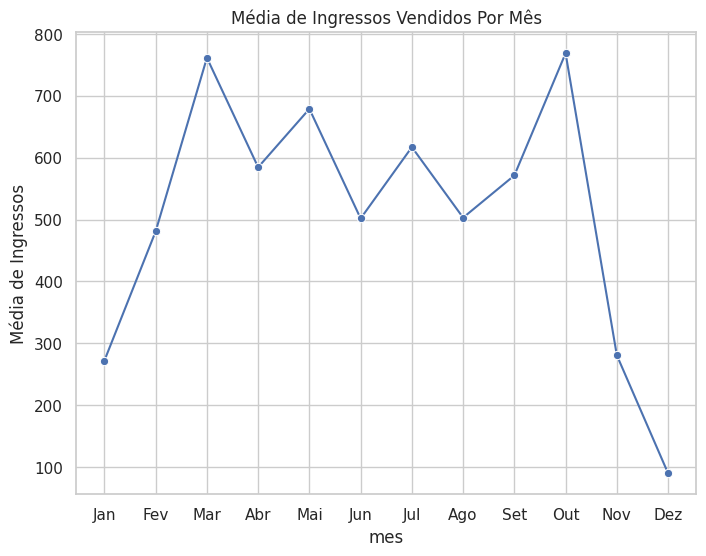

In [ ]:
# Gerando um novo DataFrame contendo os meses ordenados e o número de vendas de ingressos em cada mês (contagem)
ingressos_vendidos_por_mes = por_mes.reindex(ordem_dos_meses).reset_index()
ingressos_vendidos_por_mes.columns = ["mes", "vendas"] # Muda o nome das colunas
ingressos_vendidos_por_mes["mes"] = ingressos_vendidos_por_mes["mes"].astype(str) # Conversão de dados category -> string

sns.lineplot(data=ingressos_vendidos_por_mes, x="mes", y="vendas", marker="o", sort=False)   # sort=False mantém a ordem dos meses
plt.title("Média de Ingressos Vendidos Por Mês")
plt.ylabel("Média de Ingressos")
plt.show()

**Leitura do Gráfico**:
- As vendas de ingresso atingem um pico nos meses de Março e Outubro
- As vendas caem drasticamente nos meses de Dezembro e Janeiro

### Média de Ingressos Vendidos em Cada Mês do Ano Por Gênero Musical

In [ ]:
COLUNA_GRUPO = ["mes_venda", "ano_venda", "genero_musical"]

# agrupa por ano, mês e gênero para descobrir o total de ingressos vendidos
por_ano_mes_genero = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].count().round(2)
por_mes = por_ano_mes_genero.groupby("mes_venda").mean().round(2)

# agrupa por mês e gênero para descobrir a média de ingressos vendidos
por_mes_genero = por_ano_mes_genero.groupby(level=["mes_venda", "genero_musical"]).mean()

por_mes_genero = por_mes_genero.sort_values(ascending=False)

por_mes_genero = por_mes_genero.groupby(level="mes_venda").head(3)
top_3_por_mes = por_mes_genero.sort_index(level="mes_venda")
display(top_3_por_mes)

mes_venda  genero_musical
Jan        eletronica         38.111111
           funk               38.000000
           pop                45.777778
Fev        eletronica         72.777778
           pop                95.111111
           sertanejo          70.666667
Mar        eletronica        110.444444
           pop               144.888889
           sertanejo         119.777778
Abr        funk               93.555556
           pop               114.111111
           sertanejo          97.333333
Mai        eletronica         95.222222
           funk              111.666667
           rap               117.666667
Jun        eletronica         81.777778
           pop                69.777778
           sertanejo          77.555556
Jul        forró              92.555556
           rock               80.333333
           sertanejo         102.666667
Ago        eletronica         76.111111
           pop                70.222222
           rock               76.666667
Set        eletronica         90.555556
           funk               91.222222
           rock               85.333333
Out        eletronica        128.000000
           rock              133.444444
           sertanejo         114.222222
Nov        eletronica         40.777778
           pop                40.111111
           rock               57.222222
Dez        eletronica         15.000000
           pop                15.666667
           sertanejo          12.111111
Name: valor, dtype: float64

## Tratando Valores Ausentes e Outliers
Um outlier é um valor fora do padrão. Ele pode ser um erro de dado (como 9999 minutos de espera) ou um caso real e raro. A pergunta é sempre a mesma: ele está distorcendo o resultado?


### Regra do IQR
O que esta célula faz: usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos.

In [ ]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


### Medidas Com e Sem os Candidatos a Outlier

In [ ]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


### Leitura
- A regra do IQR marcou 4653 valores, a partir de 1104.52. Sem esses valores considerados outliers, a média cai de 469.54 para 357.40, a mediana cai de 290 para 273.09, e o desvio padrão cai de 455.12  para 238.74

### Minha Decisão: Manter os Outliers

A partir da análise exploratória feita com as métricas (contagem, média, mediana, soma, etc) de valor vendido por tipo de ingresso, é possível observar que o camarote apresenta uma média muito acima de todas as outras (1771.68) e uma contagem de vendas considerável (1771.68). Além disso, o ingresso VIP também apresenta uma média alta (812.64) com desvio padrão de 207.04 e uma contagem de 9843 vendas.

Considerando que o limite superior para um outlier é o valor 1104.52, pode-se inferir os seguintes pontos:
- Com média e mediana muito acima do limite superior de 1104.52, a maioria (ou o total) das 3797	vendas registradas como camarote são prováveis outliers
- Com média e mediana um pouco abaixo do limite superior e um desvio padrão alto, algumas das 9843 vendas registradas como vip também são prováveis outliers

Também considerando que o maior valor de venda registrado foi 2975.31, pouco mais de 1000 reais acima da média e mediana do camarote, eu acredito que todos os outliers sejam valores plausíveis para vendas.

## Lendo a Distribuição dos Valores
A distribuição mostra o formato de como os valores se espalham: concentrados no meio, inclinados para um lado ou espalhados. Três células descrevem esse formato antes de desenhar qualquer gráfico.

### Assimetria (skew)
O que esta célula faz: calcula o quanto a distribuição se inclina para um dos lados.

In [ ]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


### Percentis
O que esta célula faz: mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.

In [ ]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(2))

0.10     139.14
0.25     197.03
0.50     290.00
0.75     560.02
0.90    1028.74
Name: valor, dtype: float64


### Quantidade de Valores por Faixa
O que esta célula faz: divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [ ]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


### Leitura da Distribuição

- O valor da assimetria de 2.36 indica que há uma cauda para a direita; ou seja, a assimetria é forte e positiva
- 75% dos registros de venda ficam até 560.02, enquanto 90% dos registros ficam até 1028,74
- A maioria dos registros (43778) estão concentrados na primeira faixa de valores, enquanto as duas mais altas possuem apenas 1331 e 434 registros. É possível perceber que o total de registros diminui conforme as faixas aumentam.
- Em outras palavras: a maioria dos valores fica entre 77.65 e 659.5, e poucos passam de 2396.35

## Recomendação de Decisão

Pergunta de negócio: Quais canais de venda apresentam maior volume de ingressos vendidos e maior faturamento?

Evidência 1: A soma total das receitas de vendas (aproximadamente 19 milhões) de ingressos pelo site e pelo app do festival representa mais da metade de toda a receita gerada (aproximadamente 25 milhões).

Evidência 2: A soma total (aproximadamente 41 mil) dos ingressos vendidos pelo site e pelo app do festival também representam mais da metade de todos os ingressos vendidos (aproximadamente 55 mil).

Assim, é possível concluir que a integridade do negócio depende fortemente do bom funcionamento desses dois canais de venda.
Recomendação em uma frase: É recomendável um forte investimento em gestão de riscos relacionados a falhas nesses canais, como lentidão e proteção contra perda de dados, além de uma garantia que a experiência do usuário e os serviços de pagamento nunca deixem a desejar. Como o site e o app do festival são os dois pilares das vendas de ingressos, quaisquer erros ou falhas relacionados a eles arriscam uma grande perda de faturamento.

Limites da análise: Os dados são fictícios e os outliers de valor de venda de ingresso foram mantidos.

## Gráficos

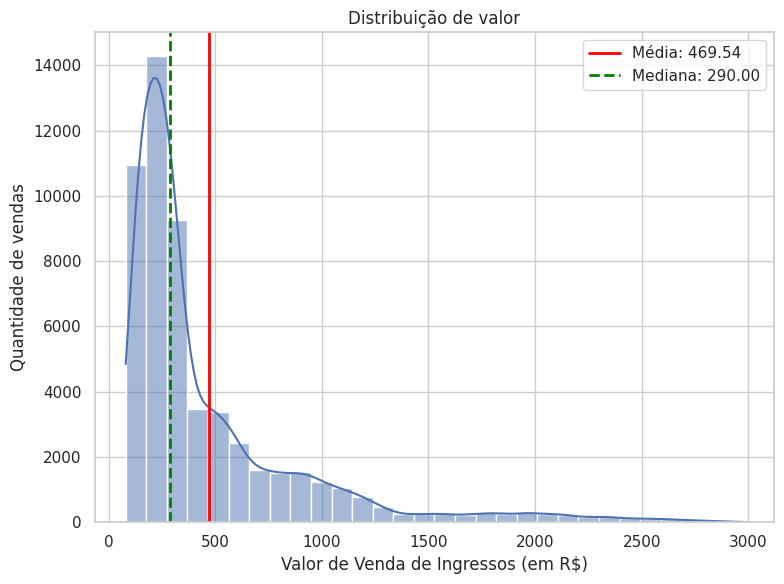

In [ ]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor de Venda de Ingressos (em R$)")
plt.ylabel("Quantidade de vendas")
plt.legend()
plt.tight_layout()
plt.show()

O gráfico acima mostra a frequência e a distribuição do valor de venda de ingressos em reais. A partir dele, é possível comprovar a assimetria à direita: as colunas mais altas se concentram na faixa entre 0 e 500 reais, diminuindo cada vez mais conforme o valor de venda aumenta. Além disso, a média (linha vermelha) é maior que a mediana (linha tracejada verde), reforçando a ideia de que há outliers distorcendo o valor da média para cima.

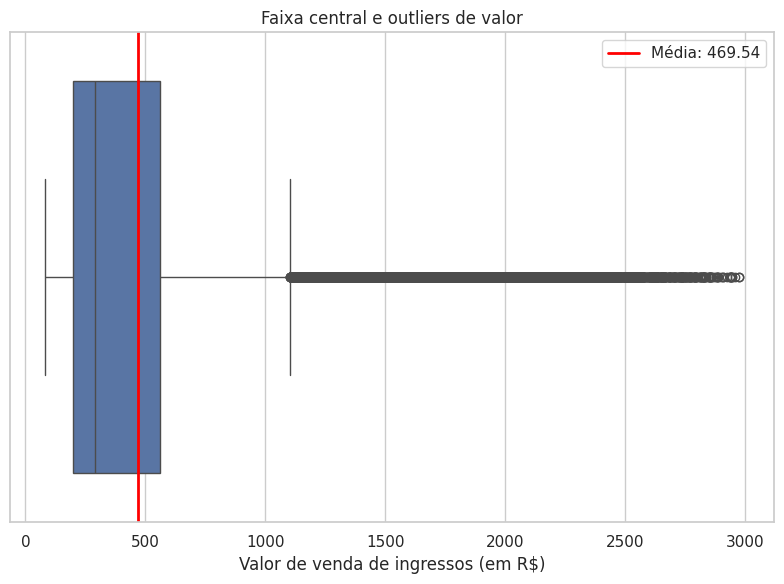

In [ ]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Valor de venda de ingressos (em R$)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O gráfico acima ilustra visualmente a existência de um grande número de outliers: os pontos pretos são tantos que acabam formando uma linha grossa preta. Porém, eles representam valores individuais que estão acima do limite superior de 1104.52.

# Ideias de Perguntas

## Quais gêneros vendem mais ao longo do tempo (e por tipo de ingresso)?

## Há sazonalidade na venda de ingressos? Se sim, é referente ao total de vendas, aos canais de vendas utilizados ou aos tipos de ingressos vendidos?

## O valor pago pelo ingresso é parecido entre as vendas ou muda muito conforme o tipo de ingresso?

## Quais gêneros musicais geram maior receita com vendas de ingressos nos festivais?

## O valor pago pelos tipos de ingresso é o mesmo em todos os canais de venda?

## A receita de ingressos vendidos muda muito conforme o canal de venda?